<div style="background-color: steelblue; padding: 10px; border-radius: 5px;">
    <p style="margin: 10;"></p>
    <h1 style="text-align: center; margin: 0; font-weight: bold; color: white;">SWOT OMIP : Seasonality ratio</h1>
    <p style="margin: 10;"></p>
</div>


## 📦**Imports** 

In [9]:
%%time

##################################
#Imports

from datetime import datetime
import s3fs
import xarray as xr
import pyinterp
from widetrax import DataPreprocessing as dp
from widetrax import Spectra as sp
import numpy as np
import json
from watermark import watermark
import time
import platform
from shapely.geometry import shape, box

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
#from widetrax import Spectra as sp
#import plot_psd1Xglobal1 as pp2X
import cum_sp_onl_season_v3 as cs
import importlib
importlib.reload(cs)
import position_function as pf


CPU times: user 738 μs, sys: 1.58 ms, total: 2.32 ms
Wall time: 1.77 ms


## **Map plot functions**

In [10]:


def plot_fig(ax,imodel,lon_edges,lat_edges,ZW,ZS,valmin,valmax,model,posx,posy):
    ax[posx,posy].add_feature(cfeature.COASTLINE)
    ax[posx,posy].add_feature(cfeature.LAND, facecolor="lightgray")
    mesh = ax[posx,posy].pcolormesh(
        lon_edges,
        lat_edges,
        np.squeeze(ZW[imodel,:,:]/ZS[imodel,:,:]),
        vmin=valmin,
        vmax=valmax,
        cmap='seismic',
        transform=ccrs.PlateCarree()
    )
    ax[posx,posy].set_title(model[imodel])
    ax[posx,posy] = ax[posx,posy].gridlines(draw_labels=True,linewidth=0.2)
    ax[posx,posy].bottom_labels = True
    ax[posx,posy].top_labels = False
    ax[posx,posy].right_labels = False
    ax[posx,posy].left_labels = True
    ax[posx,posy].xlines = False
    ax[posx,posy].ylines = False
    return ax, mesh

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
def plot_spectral_scatter(ax, k_list, specAW_list, specAS_list, specBW_list, specBS_list, labelA, labelB,abc):
    vmin = 0    # minimum color value
    vmax = 282   # maximum color value
    vmin1 = 1e-1    # minimum color value
    vmax1 = 1e1   # maximum color value


    xW_all = np.array(specAW_list)
    yW_all = np.array(specBW_list)
    xS_all = np.array(specAS_list)
    yS_all = np.array(specBS_list)
    k_all = np.array(k_list)

    # remove invalid values (needed for log scale)
    mask_valid = (xW_all > 0) & (yW_all > 0) & (xS_all > 0) & (yS_all > 0)

    # remove invalid values (needed for log scale)
    #mask_scale = (k_all >= 50) & (k_all <= 500)

    mask = mask_valid# & mask_scale
    xS_all=xS_all[mask]
    yS_all=yS_all[mask]
    xW_all=xW_all[mask]
    yW_all=yW_all[mask]
    k_all=k_all[mask]

    x_all=xW_all/xS_all
    y_all=yW_all/yS_all
    slope, intercept, r_value, p_value, std_err = linregress(x_all, y_all)
    sc = ax.scatter(
        x_all,
        y_all,
        c=k_all,
        vmin=vmin,
        vmax=vmax,
        cmap="nipy_spectral",
        s=10,
        alpha=0.7
    )

    # axis scaling
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(abc)

    vmin = min(x_all.min(), y_all.min())
    vmax = max(x_all.max(), y_all.max())

    ax.plot([vmin, vmax], [vmin, vmax], "k--")
    
    ax.set_xlim(vmin1, vmax1)
    ax.set_ylim(vmin1, vmax1)
    ax.text(x=1.2e-1, y=0.7e1, s=f"R2 = {r_value:.3f}", weight="bold")
    ax.grid(True, which="both", ls="--", alpha=0.3)
    ax.set_xlabel(labelA)
    ax.set_ylabel(labelB)

    return sc

## **Load boxes position**

In [12]:
boxesjson="mostly_ocean_boxes_filtered.geojson"
north_boxes, south_boxes=pf.position_boxes_northsouth(boxesjson)
selected=pf.position_boxes(boxesjson) # Index boxes for global ocean, and the region


North boxes: 93
South boxes: 189


## **Load Spectrum**

In [14]:
#Define Wavelength range
min_wavelength=50
max_wavelength=150
models=["GLO12V4","GLO36V1","NOC12","NOC025","LLC4320","SWOT"]

R,F=cs.season_spec(models,selected,50,500,north_boxes,south_boxes,
                                   "https://minio.dive.edito.eu/",'JFM','JAS',modeload="online",folder="project-meom-ige/OMIP/Global/")

# psdsW winter spectrum list / psdsS summer spectrum list 
psdsW, psdsS,freqJAS=cs.season_cum(models,selected,min_wavelength,max_wavelength,north_boxes,south_boxes,
                                   "https://minio.dive.edito.eu/",'JFM','JAS',modeload="online",folder="project-meom-ige/OMIP/Global/")

#  reorganice values of every boxes into a map: ZW (spectrum winter) and ZS (spectrum summer)
ZW,ZS=cs.remap(psdsW,psdsS,models)


In [15]:
#Define Wavelength range
min_wavelength=150
max_wavelength=350
models=["GLO12V4","GLO36V1","NOC12","NOC025","LLC4320","SWOT"]

# psdsW winter spectrum list / psdsS summer spectrum list 
psdsWL, psdsSL,freqJASL=cs.season_cum(models,selected,min_wavelength,max_wavelength,north_boxes,south_boxes,
                                      "https://minio.dive.edito.eu/",'JFM','JAS',modeload="online",folder="project-meom-ige/OMIP/Global/")

#  reorganice values of every boxes into a map: ZW (spectrum winter) and ZS (spectrum summer)
ZWL,ZSL=cs.remap(psdsWL,psdsSL,models)


## **Plotting**
  

In [16]:
with open("mostly_ocean_boxes_filtered.geojson") as f:
    data = json.load(f)

latboxes = []
latpos=np.arange(-70,61,10)

for i, feature in enumerate(data["features"]):
    if (i!=14) and (i!=15):
        coords = feature["geometry"]["coordinates"][0]
        first_lat = coords[0][1]  # First coord [lon, lat] → lat is index 1
        latboxes.append(first_lat)

latindex=[]
for i in latpos:
    latindex.append(np.where(latboxes==i))

print(latindex[0])

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22]),)


/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_41784/2269608726.py:110: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


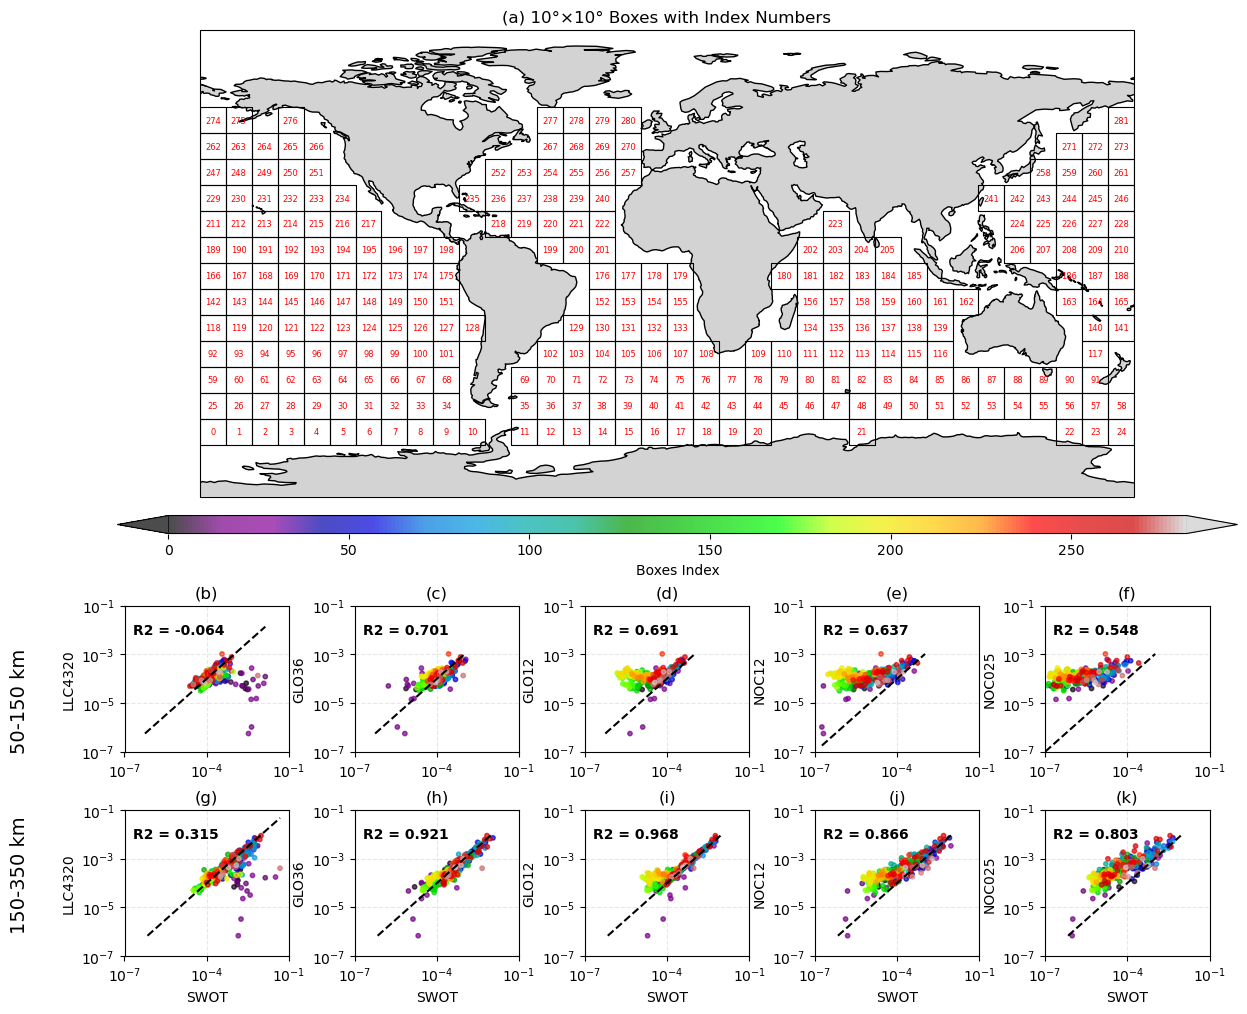

In [17]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import matplotlib.colors as mcolors

model= ["GLO12","GLO36","NOC12","NOC025","LLC4320","SWOT"]
letters=["(b)","(c)","(d)","(e)","(f)","(g)","(h)","(i)","(j)","(k)"]
lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)

valmin=0
valmax=2

fig = plt.figure(figsize=(14, 18))

# Outer grid: 3 sections
outer = fig.add_gridspec(
    3, 1,
    height_ratios=[2, 1.5, 1.5],
    hspace=0.28
)

ax_big = fig.add_subplot(
    outer[0].subgridspec(1, 1)[0],
    projection=ccrs.PlateCarree()
)

# Large subplot spanning both columns

ax_big.set_global()
ax_big.add_feature(cfeature.LAND, facecolor="lightgray")
ax_big.add_feature(cfeature.COASTLINE)

for i, feature in enumerate(data["features"]):

    poly = shape(feature["geometry"])

    # Draw box
    ax_big.add_geometries(
        [poly],
        ccrs.PlateCarree(),
        edgecolor="black",
        facecolor="none",
        linewidth=0.8
    )

    # Get box center
    lon_min, lat_min, lon_max, lat_max = poly.bounds
    lon_c = 0.5 * (lon_min + lon_max)
    lat_c = 0.5 * (lat_min + lat_max)

    # Add number
    ax_big.text(
        lon_c, lat_c,
        str(i),  # numbering from 1
        transform=ccrs.PlateCarree(),
        ha="center",
        va="center",
        fontsize=6,
        color="red"
    )

ax_big.set_title("(a) 10°×10° Boxes with Index Numbers")
#-------
# Remaining 3x2 subplots
gs_middle = outer[1].subgridspec(
    2, 5,
    hspace=0.4,
    wspace=0.4
)

ax = np.empty((2, 5), dtype=object)

for i in range(2):
    for j in range(5):
        ax[i, j] = fig.add_subplot(gs_middle[i, j])


fig.text(0.05, 0.48, '50-150 km', ha='center', fontsize=14,rotation=90)
imodel=4
sc0 = plot_spectral2_scatter(ax[0,0],np.arange(0,282),np.squeeze(psdsW[:,imodel]),np.squeeze(psdsW[:,5])," ", model[imodel],letters[0])
imodel=1
sc1 = plot_spectral2_scatter(ax[0,1],np.arange(0,282),np.squeeze(psdsW[:,imodel]),np.squeeze(psdsW[:,5])," ", model[imodel],letters[1])
imodel=0
sc2 = plot_spectral2_scatter(ax[0,2],np.arange(0,282),np.squeeze(psdsW[:,imodel]),np.squeeze(psdsW[:,5])," ", model[imodel],letters[2])
imodel=2
sc3 = plot_spectral2_scatter(ax[0,3],np.arange(0,282),np.squeeze(psdsW[:,imodel]),np.squeeze(psdsW[:,5])," ", model[imodel],letters[3])
imodel=3
sc4 = plot_spectral2_scatter(ax[0,4],np.arange(0,282),np.squeeze(psdsW[:,imodel]),np.squeeze(psdsW[:,5])," ", model[imodel],letters[4])


fig.text(0.05, 0.38, '150-350 km', ha='center', fontsize=14, rotation=90)
imodel=4
sc0L = plot_spectral2_scatter(ax[1,0],np.arange(0,282),np.squeeze(psdsWL[:,imodel]),np.squeeze(psdsWL[:,5]),"SWOT", model[imodel],letters[5])
imodel=1
sc1L = plot_spectral2_scatter(ax[1,1],np.arange(0,282),np.squeeze(psdsWL[:,imodel]),np.squeeze(psdsWL[:,5]),"SWOT", model[imodel],letters[6])
imodel=0
sc2L = plot_spectral2_scatter(ax[1,2],np.arange(0,282),np.squeeze(psdsWL[:,imodel]),np.squeeze(psdsWL[:,5]),"SWOT", model[imodel],letters[7])
imodel=2
sc3L = plot_spectral2_scatter(ax[1,3],np.arange(0,282),np.squeeze(psdsWL[:,imodel]),np.squeeze(psdsWL[:,5]),"SWOT", model[imodel],letters[8])
imodel=3
sc4L = plot_spectral2_scatter(ax[1,4],np.arange(0,282),np.squeeze(psdsWL[:,imodel]),np.squeeze(psdsWL[:,5]),"SWOT", model[imodel],letters[9])




cbar_ax = fig.add_axes([0.12, 0.6, .8, 0.01])
cbar = fig.colorbar(sc3,cax=cbar_ax, orientation='horizontal', fraction=0.02,  extend='both')
cbar.set_label("Boxes Index")
plt.tight_layout()


#------------------------------


#plt.savefig("FigV2/scatter_global_cumspectrum_modelSWOT2_winter_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False, bbox_inches="tight")
plt.show()


/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_41784/2373583453.py:110: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


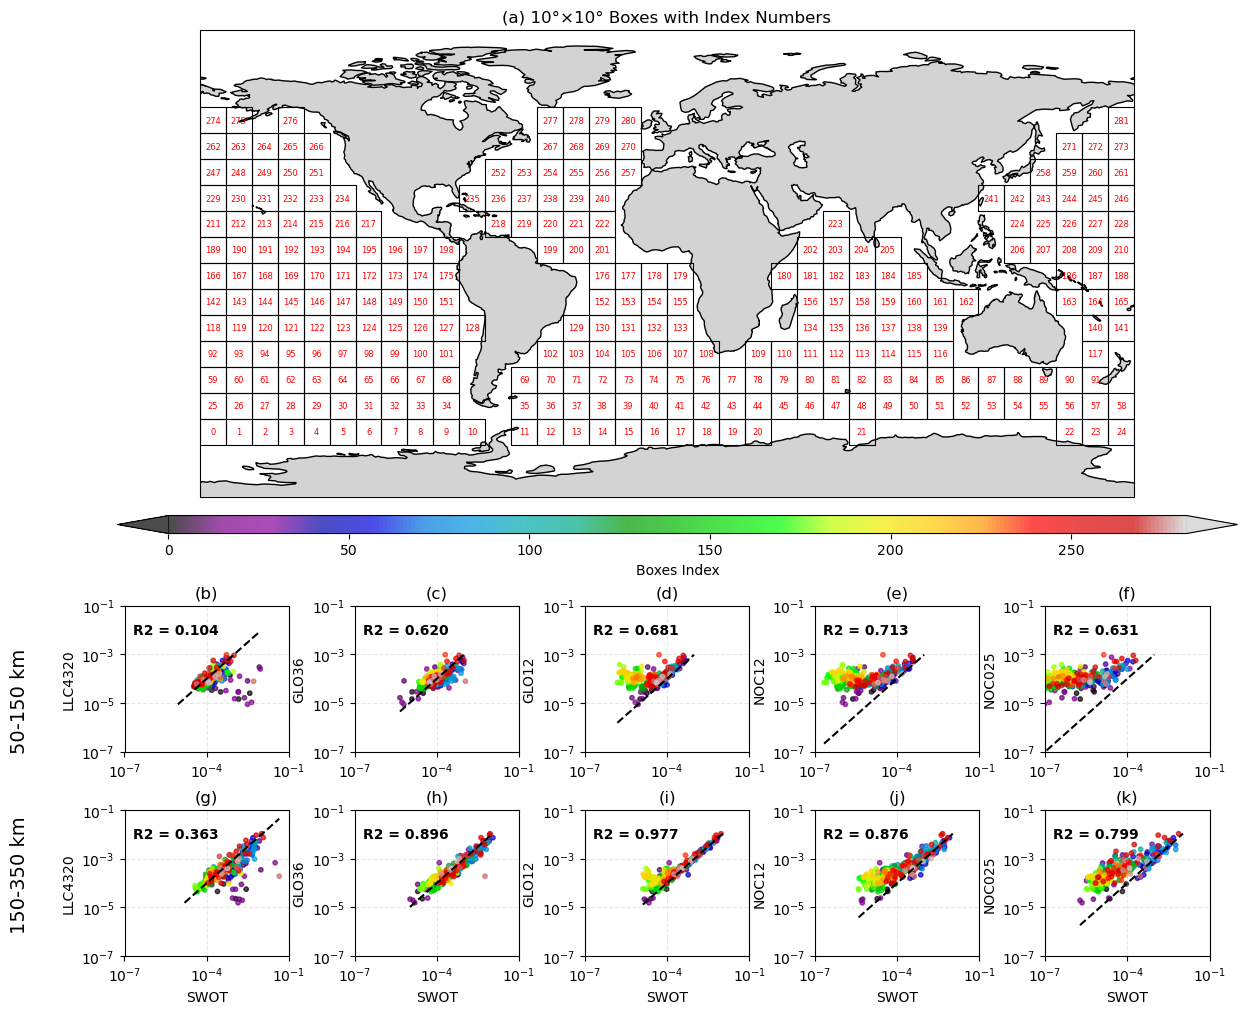

In [18]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import matplotlib.colors as mcolors

model= ["GLO12","GLO36","NOC12","NOC025","LLC4320","SWOT"]
letters=["(b)","(c)","(d)","(e)","(f)","(g)","(h)","(i)","(j)","(k)"]
lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)

valmin=0
valmax=2

fig = plt.figure(figsize=(14, 18))

# Outer grid: 3 sections
outer = fig.add_gridspec(
    3, 1,
    height_ratios=[2, 1.5, 1.5],
    hspace=0.28
)

ax_big = fig.add_subplot(
    outer[0].subgridspec(1, 1)[0],
    projection=ccrs.PlateCarree()
)

# Large subplot spanning both columns

ax_big.set_global()
ax_big.add_feature(cfeature.LAND, facecolor="lightgray")
ax_big.add_feature(cfeature.COASTLINE)

for i, feature in enumerate(data["features"]):

    poly = shape(feature["geometry"])

    # Draw box
    ax_big.add_geometries(
        [poly],
        ccrs.PlateCarree(),
        edgecolor="black",
        facecolor="none",
        linewidth=0.8
    )

    # Get box center
    lon_min, lat_min, lon_max, lat_max = poly.bounds
    lon_c = 0.5 * (lon_min + lon_max)
    lat_c = 0.5 * (lat_min + lat_max)

    # Add number
    ax_big.text(
        lon_c, lat_c,
        str(i),  # numbering from 1
        transform=ccrs.PlateCarree(),
        ha="center",
        va="center",
        fontsize=6,
        color="red"
    )

ax_big.set_title("(a) 10°×10° Boxes with Index Numbers")
#-------
# Remaining 3x2 subplots
gs_middle = outer[1].subgridspec(
    2, 5,
    hspace=0.4,
    wspace=0.4
)

ax = np.empty((2, 5), dtype=object)

for i in range(2):
    for j in range(5):
        ax[i, j] = fig.add_subplot(gs_middle[i, j])


fig.text(0.05, 0.48, '50-150 km', ha='center', fontsize=14,rotation=90)
imodel=4
sc0 = plot_spectral2_scatter(ax[0,0],np.arange(0,282),np.squeeze(psdsS[:,imodel]),np.squeeze(psdsS[:,5])," ", model[imodel],letters[0])
imodel=1
sc1 = plot_spectral2_scatter(ax[0,1],np.arange(0,282),np.squeeze(psdsS[:,imodel]),np.squeeze(psdsS[:,5])," ", model[imodel],letters[1])
imodel=0
sc2 = plot_spectral2_scatter(ax[0,2],np.arange(0,282),np.squeeze(psdsS[:,imodel]),np.squeeze(psdsS[:,5])," ", model[imodel],letters[2])
imodel=2
sc3 = plot_spectral2_scatter(ax[0,3],np.arange(0,282),np.squeeze(psdsS[:,imodel]),np.squeeze(psdsS[:,5])," ", model[imodel],letters[3])
imodel=3
sc4 = plot_spectral2_scatter(ax[0,4],np.arange(0,282),np.squeeze(psdsS[:,imodel]),np.squeeze(psdsS[:,5])," ", model[imodel],letters[4])


fig.text(0.05, 0.38, '150-350 km', ha='center', fontsize=14, rotation=90)
imodel=4
sc0L = plot_spectral2_scatter(ax[1,0],np.arange(0,282),np.squeeze(psdsSL[:,imodel]),np.squeeze(psdsSL[:,5]),"SWOT", model[imodel],letters[5])
imodel=1
sc1L = plot_spectral2_scatter(ax[1,1],np.arange(0,282),np.squeeze(psdsSL[:,imodel]),np.squeeze(psdsSL[:,5]),"SWOT", model[imodel],letters[6])
imodel=0
sc2L = plot_spectral2_scatter(ax[1,2],np.arange(0,282),np.squeeze(psdsSL[:,imodel]),np.squeeze(psdsSL[:,5]),"SWOT", model[imodel],letters[7])
imodel=2
sc3L = plot_spectral2_scatter(ax[1,3],np.arange(0,282),np.squeeze(psdsSL[:,imodel]),np.squeeze(psdsSL[:,5]),"SWOT", model[imodel],letters[8])
imodel=3
sc4L = plot_spectral2_scatter(ax[1,4],np.arange(0,282),np.squeeze(psdsSL[:,imodel]),np.squeeze(psdsSL[:,5]),"SWOT", model[imodel],letters[9])




cbar_ax = fig.add_axes([0.12, 0.6, .8, 0.01])
cbar = fig.colorbar(sc3,cax=cbar_ax, orientation='horizontal', fraction=0.02,  extend='both')
cbar.set_label("Boxes Index")
plt.tight_layout()


#------------------------------


#plt.savefig("FigV2/scatter_global_cumspectrum_modelSWOT2_summer_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False, bbox_inches="tight")
plt.show()
